## This is a sanity check

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
flexpartoutput_filename = '/jetfs/scratch/gbrack/flexpart_output/india_single_10d/grid_time_20150528120000.nc'
era5_filename = '/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_Pr.nc'

In [3]:
era = xr.open_dataset(era5_filename)
flexpart = xr.open_dataset(flexpartoutput_filename)
partoutput = xr.open_mfdataset('/jetfs/scratch/gbrack/flexpart_output/india_single_10d/partoutput_*.nc')

In [4]:
era_clean = era.rename({'valid_time': 'time'})
era_aligned = era_clean.reindex_like(flexpart)

In [5]:
initial_cond = partoutput.isel(time=-1)
end_cond = partoutput.isel(time=0)

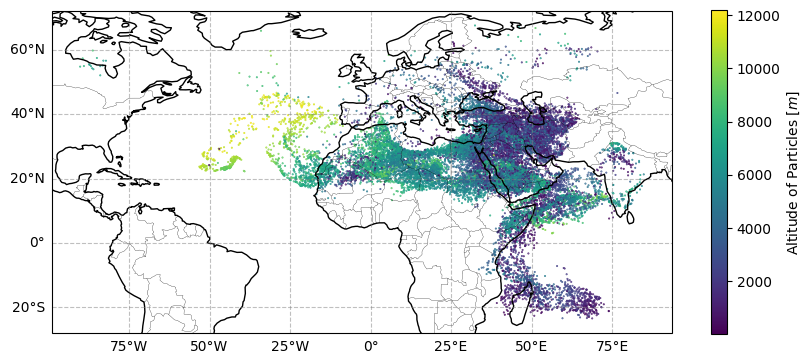

In [6]:
# lets look at the location of the particles at the first timestep

fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

scatter = ax.scatter(initial_cond.lon_av, initial_cond.lat_av, s=0.2, transform=ccrs.PlateCarree(), c=initial_cond.z_av, cmap='viridis')

plt.colorbar(scatter, label=r'Altitude of Particles $[m]$', shrink=0.7)

gl = ax.gridlines(draw_labels=True, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)

In [7]:
cp = 1004.6
Lv = 2501000
g = 9.81

MSE_initial = (cp * initial_cond.T_av) + (Lv * initial_cond.sh) + (g * initial_cond.z_av)
MSE_end = (cp * end_cond.T_av) + (Lv * end_cond.sh) + (g * end_cond.z_av)

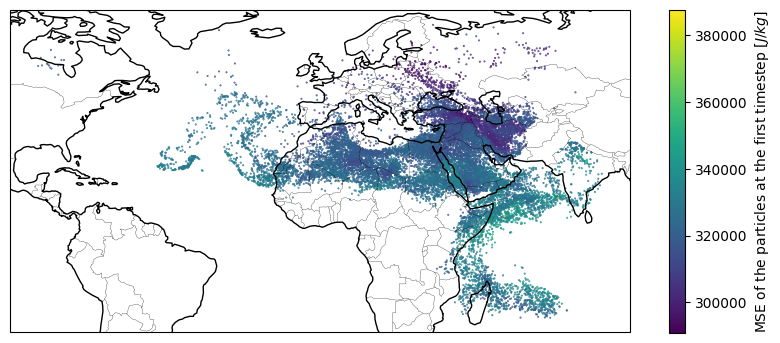

In [8]:
# let's look at the moist static energy of the particles at the first timestep

fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

scatter = ax.scatter(initial_cond.lon_av, initial_cond.lat_av, s=0.2, transform=ccrs.PlateCarree(), c=MSE_initial, cmap='viridis')

plt.colorbar(scatter, label=r'MSE of the particles at the first timestep $[J/kg]$', shrink=0.7)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)

In [9]:
absolute_initial_MSE = MSE_initial.mean().values
print(f'Absolute initial MSE: {absolute_initial_MSE:.1f} J/kg')

Absolute initial MSE: 321744.3 J/kg


In [10]:
absolute_end_MSE = MSE_end.mean().values
print(f'Absolute final MSE: {absolute_end_MSE:.1f} J/kg')

Absolute final MSE: 342365.9 J/kg


In [11]:
lon_initial = initial_cond.lon_av
lat_initial = initial_cond.lat_av


print(f"West: {lon_initial.min().values - 5}")  # Minus 5 for the safety buffer
print(f"East: {lon_initial.max().values + 5}")
print(f"South: {lat_initial.min().values - 5}")
print(f"North: {lat_initial.max().values + 5}")

West: -4.989127725362778
East: 364.9735107421875
South: -28.418193817138672
North: 72.56858825683594


## Now let's get that $\Delta E$

In [12]:
residence_time = flexpart['spec001_mr'].sel(height=100).squeeze()
sshf = era_aligned['sshf']
slhf = era_aligned['slhf']

In [13]:
dt = 3600
rho = 1.2

In [14]:
#hourly_sh = (residence_time * (sshf * -1.0)) / (dt * 100 * rho)
#hourly_lh = (residence_time * (slhf * -1.0)) / (dt * 100 * rho)

hourly_sh = (residence_time * (sshf * -1.0)) / (dt * 100)
hourly_lh = (residence_time * (slhf * -1.0)) / (dt * 100)

In [15]:
total_sensible_added = hourly_sh.sum().values
total_latent_added = hourly_lh.sum().values

total_energy_added = total_sensible_added + total_latent_added

In [16]:
print(f"Target to find: 20602.0 J/kg")
print(f"Total Sensible Heat added: {total_sensible_added:.1f} J/kg")
print(f"Total Latent Heat added:   {total_latent_added:.1f} J/kg")
print(f"---")
print(f"TOTAL SURFACE FORCING:     {total_energy_added:.1f} J/kg")

Target to find: 20602.0 J/kg
Total Sensible Heat added: 12677.2 J/kg
Total Latent Heat added:   9286.1 J/kg
---
TOTAL SURFACE FORCING:     21963.3 J/kg


## Let's look at the $\Delta E$ distribution

In [17]:
# sum up energy uptake through time
total_sensible = hourly_sh.sum(dim='time')
total_latent = hourly_lh.sum(dim='time')

Text(0.5, 1.0, 'Total Sensible Heat Energy Accumulated over 10 Days')

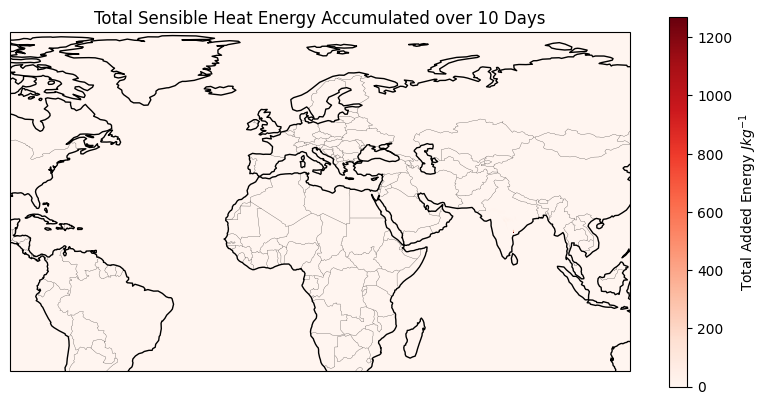

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

max_energy = total_sensible.max().values

my_min = 0
my_max = np.round(max_energy, 0)

mesh = ax.pcolormesh(total_sensible.longitude,
                     total_sensible.latitude,
                     total_sensible,
                     transform=ccrs.PlateCarree(),
                     cmap='Reds',
                     vmin=my_min,
                     vmax=my_max
                    )

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Energy $J kg^{-1}$')

ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)
ax.add_feature(cfeature.COASTLINE)

ax.set_title('Total Sensible Heat Energy Accumulated over 10 Days')

Text(0.5, 1.0, 'Total Latent Heat Energy Accumulated over 10 Days')

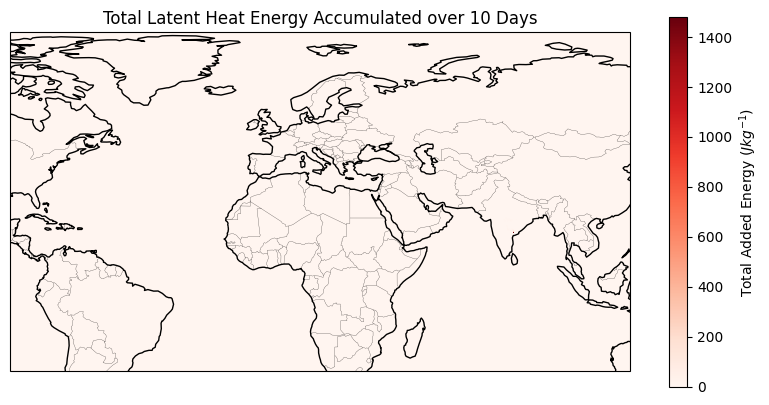

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

max_energy = total_latent.max().values

my_min = 0
my_max = np.round(max_energy, 0)

mesh = ax.pcolormesh(total_latent.longitude,
                     total_latent.latitude,
                     total_latent,
                     transform=ccrs.PlateCarree(),
                     cmap='Reds',
                     vmin=my_min,
                     vmax=my_max
                    )

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Energy ($J kg^{-1}$)')

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

ax.set_title('Total Latent Heat Energy Accumulated over 10 Days')

In [20]:
timeline_sh = hourly_sh.sum(dim=['latitude', 'longitude'])
timeline_lh = hourly_lh.sum(dim=['latitude', 'longitude'])

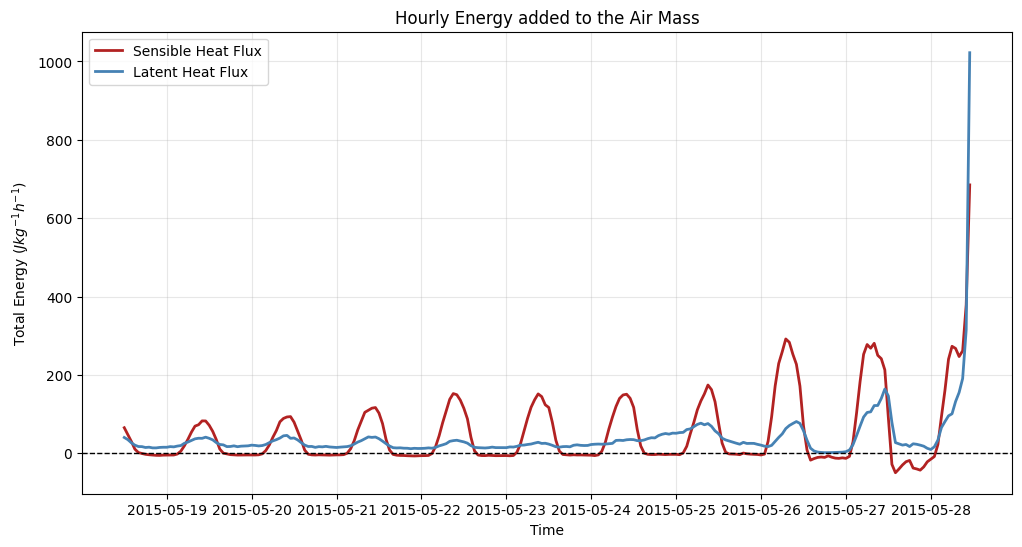

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.plot(timeline_sh.time,
        timeline_sh,
        color='firebrick',
        label='Sensible Heat Flux',
        lw=2
       )

ax.plot(timeline_lh.time,
        timeline_lh,
        color='steelblue',
        label='Latent Heat Flux',
        lw=2
       )

ax.axhline(0, c='k', lw='1', ls='--')

ax.set_title('Hourly Energy added to the Air Mass')
ax.set_ylabel(r'Total Energy ($J kg^{-1} h^{-1}$)')
ax.set_xlabel('Time')

ax.grid(True, alpha=0.3)
ax.legend()

## Okay let's do a little logarithmic scale to not ignore the starting point but also see other energy uptakes

Text(0.5, 1.0, 'Total Sensible Heat Energy Accumulated over 10 Days')

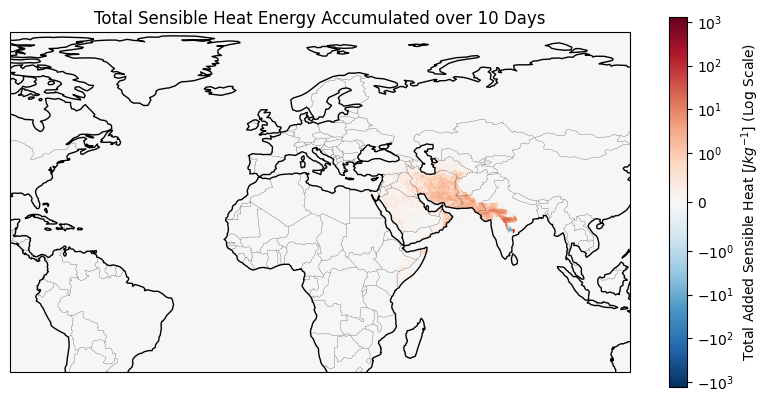

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

mesh = ax.pcolormesh(total_sensible.longitude,
                     total_sensible.latitude,
                     total_sensible,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_sensible.max(),
                                             vmax=total_sensible.max(),
                                             base=10
                     )
)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Sensible Heat $[J kg^{-1}]$ (Log Scale)')
ax.set_title('Total Sensible Heat Energy Accumulated over 10 Days')

Text(0.5, 1.0, 'Total Latent Heat Energy Accumulated over 10 Days')

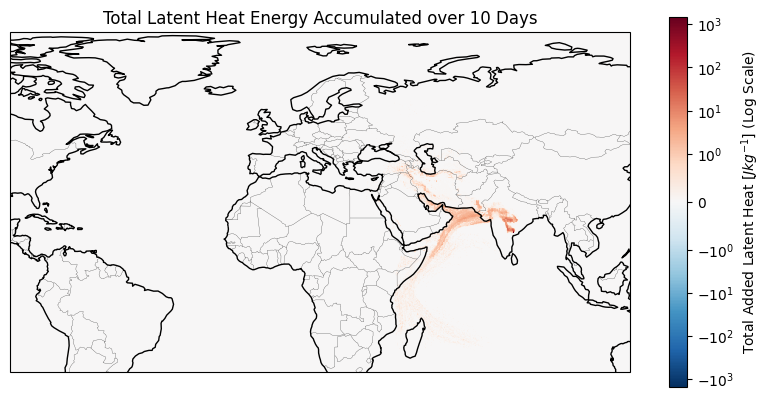

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

mesh = ax.pcolormesh(total_latent.longitude,
                     total_latent.latitude,
                     total_latent,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_latent.max(),
                                             vmax=total_latent.max(),
                                             base=10
                     )
)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Latent Heat $[J kg^{-1}]$ (Log Scale)')
ax.set_title('Total Latent Heat Energy Accumulated over 10 Days')

Text(0.5, 1.0, 'Total Sensible and Latent Heat Energy Accumulated over 10 Days')

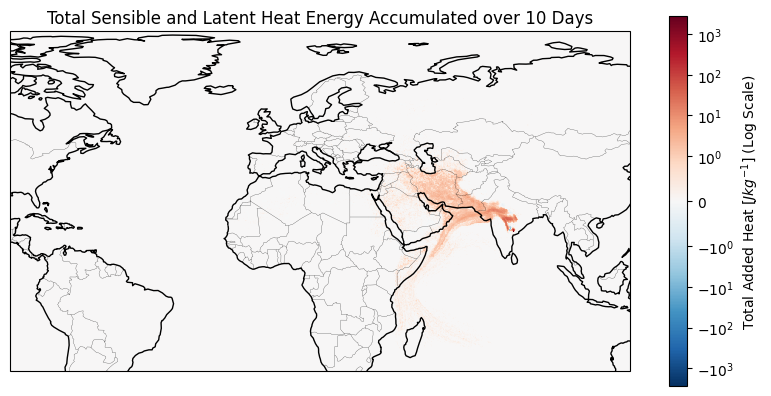

In [24]:
total_energy = total_latent + total_sensible

fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()}
                      )

mesh = ax.pcolormesh(total_energy.longitude,
                     total_energy.latitude,
                     total_energy,
                     transform=ccrs.PlateCarree(),
                     cmap='RdBu_r',
                     norm=mcolors.SymLogNorm(linthresh=1.0,
                                             vmin=-total_energy.max(),
                                             vmax=total_energy.max(),
                                             base=10
                     )
)

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2, alpha=0.8)

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Heat $[J kg^{-1}]$ (Log Scale)')
ax.set_title('Total Sensible and Latent Heat Energy Accumulated over 10 Days')